In [3]:
import pandas as pd
df = pd.read_excel("Sample data (1).xlsx")
df.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014


In [4]:
df.shape

(700, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        647 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9    Sales               700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[ns]
 13  Month Number         700 non-null  

In [6]:
df.describe()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1608.294286,96.477143,118.428571,1.827594e+05,13150.354629,1.696091e+05,145475.211429,24133.860371,2014-04-28 21:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,2013-09-01 00:00:00,1.000000,2013.000000
25%,905.000000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,2805.960000,2013-12-24 06:00:00,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,9242.200000,2014-05-16 12:00:00,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.343750,2.610775e+05,245607.500000,22662.000000,2014-09-08 12:00:00,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-12-01 00:00:00,12.000000,2014.000000
std,867.427859,108.602612,136.775515,2.542623e+05,22962.928775,2.367263e+05,203865.506118,42760.626563,NaN,3.377321,0.433322


In [7]:
df.columns = df.columns.str.strip()
df.columns

Index(['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold',
       'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts',
       'Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name',
       'Year'],
      dtype='object')

In [8]:
df.isnull().sum()

,0
Segment,0
Country,0
Product,0
Discount Band,53
Units Sold,0
Manufacturing Price,0
Sale Price,0
Gross Sales,0
Discounts,0
Sales,0


In [9]:
df[df["Discount Band"].isnull()]["Discounts"].describe()

,Discounts
count,53.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


In [10]:
df["Discount Band"] = df["Discount Band"].fillna("None")
df["Discount Band"].value_counts()

,count
Discount Band,
High,245
Medium,242
Low,160
None,53


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
((df["Gross Sales"] - df["Discounts"] - df["Sales"]).abs() > 1).sum()
((df["Sales"] - df["COGS"] - df["Profit"]).abs() > 1).sum()

np.int64(0)

In [13]:
df["Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)
df.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year,Margin %
0,Government,Germany,Carretera,None,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014,25.71
1,Government,Germany,Paseo,None,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014,25.71
2,Government,Canada,Paseo,None,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013,25.71
3,Government,Germany,Paseo,None,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014,25.71
4,Government,Germany,Velo,None,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014,25.71


In [15]:
df.to_csv("clean_sales.csv", index=False)

In [16]:
df.groupby("Segment")[["Sales","Profit"]].sum().sort_values("Profit", ascending=False)

,Sales,Profit
Segment,,
Government,5.250426e+07,1.138817e+07
Small Business,4.242792e+07,4.143168e+06
Channel Partners,1.800594e+06,1.316803e+06
Midmarket,2.381883e+06,6.601031e+05
Enterprise,1.961169e+07,-6.145456e+05


In [17]:
df.groupby("Country")[["Sales","Profit"]].sum().sort_values("Profit", ascending=False)

,Sales,Profit
Country,,
France,2.435417e+07,3781020.780
Germany,2.350534e+07,3680388.820
Canada,2.488765e+07,3529228.885
United States of America,2.502983e+07,2995540.665
Mexico,2.094935e+07,2907523.110


In [18]:
df.groupby("Product")[["Units Sold","Sales","Profit"]].sum().sort_values("Profit", ascending=False)

,Units Sold,Sales,Profit
Product,,,
Paseo,338239.5,3.301114e+07,4797437.950
VTT,168783.0,2.051192e+07,3034608.020
Amarilla,155315.0,1.774712e+07,2814104.060
Velo,162424.5,1.825006e+07,2305992.465
Montana,154198.0,1.539080e+07,2114754.880
Carretera,146846.0,1.381531e+07,1826804.885


In [19]:
df.groupby("Year")[["Sales","Profit"]].sum()

,Sales,Profit
Year,,
2013,26415255.51,3878464.51
2014,92311094.75,13015237.75


In [20]:
df.groupby(["Year","Month Number"])["Sales"].sum()

Year  Month Number
2013  9                4484000.03
      10               9295611.10
      11               7267203.30
      12               5368441.08
2014  1                6607761.68
      2                7297531.39
      3                5586859.87
      4                6964775.07
      5                6210211.06
      6                9518893.82
      7                8102920.18
      8                5864622.42
      9                6398697.24
      10              12375819.92
      11               5384214.20
      12              11998787.90
Name: Sales, dtype: float64

In [21]:
df.groupby("Discount Band")[["Discounts","Profit"]].sum()
df.groupby("Discount Band")["Margin %"].mean().round(2)

,Margin %
Discount Band,
High,24.48
Low,28.77
Medium,28.74
None,37.27


In [22]:
loss = df[df["Profit"] < 0]
print(len(loss))
loss.groupby(["Product","Segment"]).size()

58


,,0
Product,Segment,
Amarilla,Enterprise,9
Carretera,Enterprise,12
Montana,Enterprise,5
Paseo,Enterprise,11
VTT,Enterprise,8
Velo,Enterprise,13


<Axes: title={'center': 'Profit by Segment'}, ylabel='Segment'>

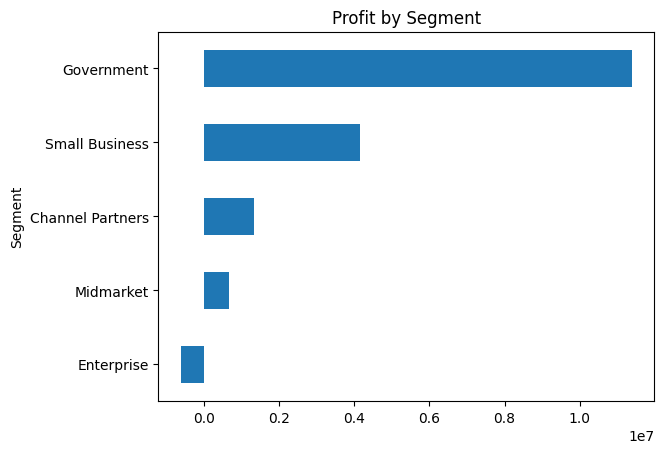

In [23]:
df.groupby("Segment")["Profit"].sum().sort_values().plot(kind="barh", title="Profit by Segment")

<Axes: title={'center': 'Profit by Product'}, ylabel='Product'>

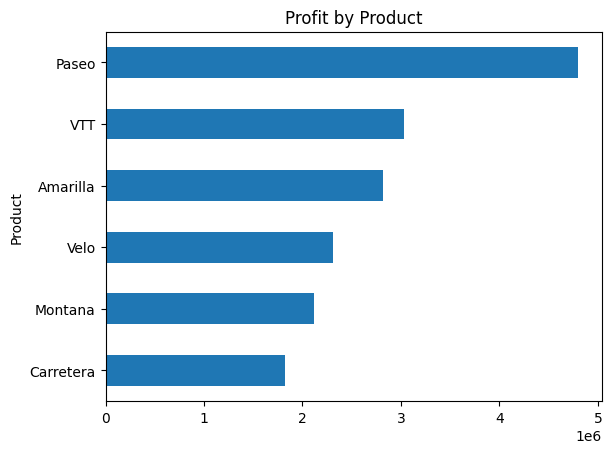

In [24]:
df.groupby("Product")["Profit"].sum().sort_values().plot(kind="barh", title="Profit by Product")

<Axes: title={'center': 'Monthly Sales'}, xlabel='Year,Month Number'>

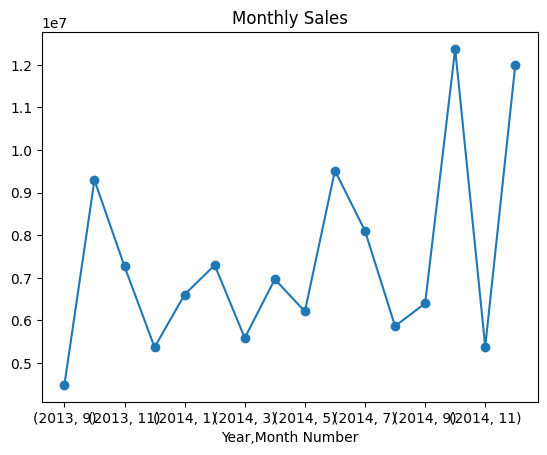

In [25]:
df.groupby(["Year","Month Number"])["Sales"].sum().plot(kind="line", title="Monthly Sales", marker="o")

In [28]:
pd.options.display.float_format = '{:,.2f}'.format

seg = df.groupby("Segment")[["Units Sold","Gross Sales","Discounts","Sales","COGS","Profit"]].sum()
seg["price_per_unit"] = seg["Gross Sales"] / seg["Units Sold"]
seg["cost_per_unit"]  = seg["COGS"] / seg["Units Sold"]
seg["discount_pct"]   = seg["Discounts"] / seg["Gross Sales"] * 100
seg[["price_per_unit","cost_per_unit","discount_pct","Profit"]]

,price_per_unit,cost_per_unit,discount_pct,Profit
Segment,,,,
Channel Partners,12.00,3.00,6.95,"1,316,803.14"
Enterprise,125.00,120.00,6.92,"-614,545.62"
Government,119.83,87.36,6.91,"11,388,173.17"
Midmarket,15.00,10.00,7.77,"660,103.07"
Small Business,300.00,250.00,7.65,"4,143,168.50"


In [29]:
pd.crosstab(df["Segment"], df["Discount Band"])

Discount Band,High,Low,Medium,None
Segment,,,,
Channel Partners,35,25,30,10
Enterprise,33,36,25,6
Government,104,57,119,20
Midmarket,41,18,28,13
Small Business,32,24,40,4


<Axes: title={'center': 'Profit by Segment'}, ylabel='Segment'>

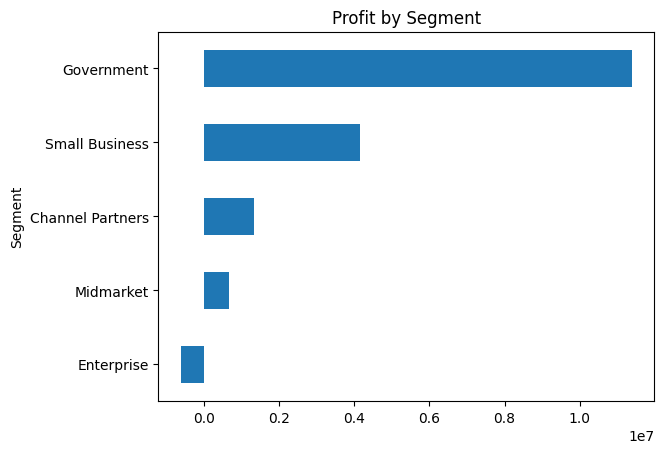

In [30]:
df.groupby("Segment")["Profit"].sum().sort_values().plot(kind="barh", title="Profit by Segment")

<Axes: title={'center': 'Profit by Product'}, ylabel='Product'>

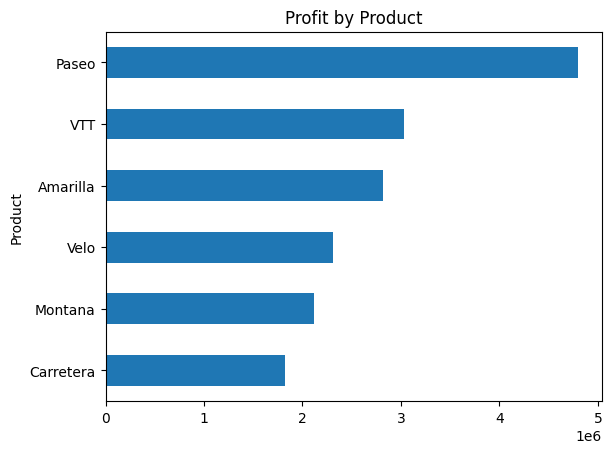

In [31]:
df.groupby("Product")["Profit"].sum().sort_values().plot(kind="barh", title="Profit by Product")

<Axes: title={'center': 'Monthly Sales'}, xlabel='Year,Month Number'>

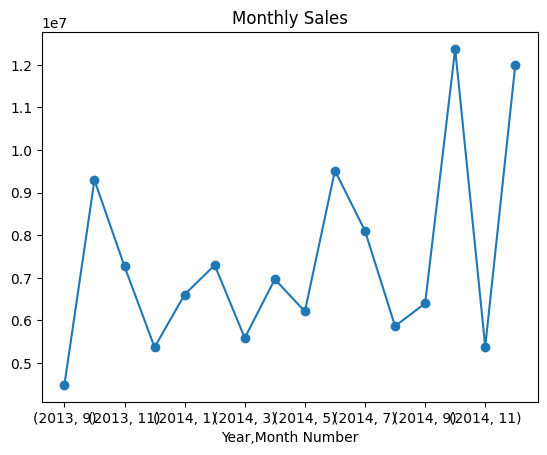

In [32]:
df.groupby(["Year","Month Number"])["Sales"].sum().plot(kind="line", marker="o", title="Monthly Sales")

In [33]:
ent = df[df["Segment"] == "Enterprise"]
print("Enterprise discounts total:", round(ent["Discounts"].sum()))
print("Enterprise profit:", round(ent["Profit"].sum()))
print(ent.groupby("Discount Band")["Profit"].agg(["count","sum"]).round(0))

Enterprise discounts total: 1457306
Enterprise profit: -614546
               count         sum
Discount Band                   
High              33 -622,369.00
Low               36  101,776.00
Medium            25 -154,952.00
None               6   61,000.00
